# Road Pavement Soil Moisture Prediction Using Multi-Output Regression

## Objective
We are developing and evaluateing a single multi-output regression pipeline for predicting the five pavement sensor targets (`Port 1`–`Port 5`) from the climate dataset collected from <a href= "https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land-timeseries?tab=download"> here</a>. It uses chronological train/validation/test splits, leakage-aware preprocessing, feature-group experiments, model comparison, an optional time-series tuning where necessary, residual diagnostics, and interpretation.

**Main prediction output:** `data/soil_moisture_predictions.csv`  
**Final model:** `models/best_multioutput_soil_moisture_model.joblib`



## 1. Setup and reproducibility

Before anything we create the required directories, sets a fixed random seed, and checks the exact 21-column source schema. 
It does not fabricate source data.

In [18]:
from pathlib import Path
import json, time, warnings, platform, sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    explained_variance_score, median_absolute_error
)
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import joblib


warnings.filterwarnings('ignore')


SEED = 42
np.random.seed(SEED)
ROOT = Path(".").resolve()
DATA_DIR = ROOT / "data/processed"
MODEL_DIR = ROOT / "models"
NOTEBOOK_DIR = ROOT / "notebooks"
for directory in (DATA_DIR, MODEL_DIR, NOTEBOOK_DIR):
    directory.mkdir(parents=True, exist_ok=True)

INPUT_PATH = DATA_DIR / "merged_cleaned_data.csv"
PREDICTION_PATH = DATA_DIR / "soil_moisture_predictions.csv"
MODEL_PATH = MODEL_DIR / "best_multioutput_soil_moisture_model.joblib"
METADATA_PATH = MODEL_DIR / "model_metadata.json"
COMPARISON_PATH = MODEL_DIR / "model_comparison.csv"
IMPORTANCE_PATH = MODEL_DIR / "feature_importance.csv"

TIME_COL = "valid_time"
TARGET_COLS = ["Port 1", "Port 2", "Port 3", "Port 4", "Port 5"]
ENVIRONMENTAL_COLS = [
    "2m_dewpoint_temperature", "total_precipitation",
    "surface_solar_radiation_downward", "surface_thermal_radiation_downward",
    "surface_temperature", "soil_temperature_level_1", "soil_temperature_level_2",
    "soil_temperature_level_3", "soil_temperature_level_4",
    "10m_u_component_of_wind", "10m_v_component_of_wind",
    "volumetric_soil_water_level_1", "volumetric_soil_water_level_2",
    "volumetric_soil_water_level_3", "volumetric_soil_water_level_4"
]
EXPECTED_COLUMNS = [TIME_COL] + ENVIRONMENTAL_COLS + TARGET_COLS
PREDICTION_COLUMNS = [
    "valid_time",
    "Actual Port 1", "Predicted Port 1", "Port 1 Error",
    "Actual Port 2", "Predicted Port 2", "Port 2 Error",
    "Actual Port 3", "Predicted Port 3", "Port 3 Error",
    "Actual Port 4", "Predicted Port 4", "Port 4 Error",
    "Actual Port 5", "Predicted Port 5", "Port 5 Error",
    "Average Predicted", "Average Actual", "Average Error"
]
FORECAST_HORIZON_ROWS = 1  # 1 means predict the next observed row; adjust to match project needs.
LAG_STEPS = [1, 2, 3]
ROLLING_WINDOWS = [3, 6]
MIN_ROWS_FOR_SPLIT = 30

print("Python:", platform.python_version())
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
print("Expected input:", INPUT_PATH)
if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Required input dataset was not found at: {INPUT_PATH}\n"
        "Place the original CSV at data/raw_dataset.csv, then rerun the notebook. "
        "No synthetic or fabricated source data will be created."
    )


Python: 3.12.8
pandas: 2.3.3 | scikit-learn: 1.6.1
Expected input: C:\Users\HomePC\Desktop\sensors-model\moisture-sensor\data\processed\merged_cleaned_data.csv


## 2. Load and validate the dataset

The timestamp is parsed as UTC, rows are sorted chronologically, duplicate timestamps are reported, and the source schema is checked. Missing or unexpected columns are reported explicitly rather than silently renamed or invented.

In [3]:
df_raw = pd.read_csv(INPUT_PATH)
missing_columns = [c for c in EXPECTED_COLUMNS if c not in df_raw.columns]
extra_columns = [c for c in df_raw.columns if c not in EXPECTED_COLUMNS]
print("Raw shape:", df_raw.shape)
print("Missing expected columns:", missing_columns)
print("Additional columns:", extra_columns)
if missing_columns:
    raise ValueError(f"Input CSV is missing required columns: {missing_columns}")

df = df_raw[EXPECTED_COLUMNS].copy()
df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="coerce", utc=True)
for col in ENVIRONMENTAL_COLS + TARGET_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
bad_times = int(df[TIME_COL].isna().sum())
if bad_times:
    print(f"Warning: dropping {bad_times} rows with invalid timestamps.")
    df = df.dropna(subset=[TIME_COL])
duplicate_times = int(df[TIME_COL].duplicated().sum())
print("Duplicate timestamps:", duplicate_times)
if duplicate_times:
    print("Keeping the last row for each duplicate timestamp; inspect duplicates before relying on results.")
    df = df.drop_duplicates(subset=[TIME_COL], keep="last")
df = df.sort_values(TIME_COL).reset_index(drop=True)
if len(df) < MIN_ROWS_FOR_SPLIT:
    raise ValueError(
        f"Only {len(df)} rows are available. This notebook's chronological 70/15/15 "
        f"evaluation needs at least {MIN_ROWS_FOR_SPLIT} rows for a minimally useful split. "
        "Use a documented time-series cross-validation strategy or collect more observations."
    )
display(df.head())
display(df.describe(include="all").T)

Raw shape: (8817, 22)
Missing expected columns: []
Additional columns: ['soil_moisture_mean']
Duplicate timestamps: 0


,valid_time,2m_dewpoint_temperature,total_precipitation,surface_solar_radiation_downward,surface_thermal_radiation_downward,surface_temperature,soil_temperature_level_1,soil_temperature_level_2,soil_temperature_level_3,soil_temperature_level_4,...,10m_v_component_of_wind,volumetric_soil_water_level_1,volumetric_soil_water_level_2,volumetric_soil_water_level_3,volumetric_soil_water_level_4,Port 1,Port 2,Port 3,Port 4,Port 5
0,2023-02-28 20:00:00+00:00,284.82748,0.0,0.0,1217556.0,291.75702,294.91772,297.85205,297.11030,296.06525,...,0.355911,0.135178,0.161331,0.164734,0.17363,2533.0,2799.0,2764.0,2771.0,2765.0
1,2023-02-28 22:00:00+00:00,284.80720,0.0,0.0,1210456.0,289.91904,293.44373,297.48633,297.11047,296.06818,...,0.416901,0.135147,0.161331,0.164734,0.17363,2533.0,2799.0,2764.0,2771.0,2764.0
2,2023-03-01 00:00:00+00:00,284.67810,0.0,0.0,1175936.0,288.47370,292.27185,297.06268,297.10900,296.06918,...,0.315567,0.135132,0.161331,0.164734,0.17363,2533.0,2798.0,2764.0,2771.0,2763.0
3,2023-03-01 02:00:00+00:00,283.82343,0.0,0.0,1161795.2,287.18700,291.23007,296.59082,297.10175,296.07016,...,0.928314,0.135117,0.161316,0.164734,0.17363,2533.0,2798.0,2764.0,2771.0,2763.0
4,2023-03-01 04:00:00+00:00,283.31420,0.0,22410.0,1150341.0,286.41130,290.45868,296.10257,297.09260,296.07114,...,1.007843,0.135117,0.161316,0.164734,0.17363,2533.0,2798.0,2764.0,2771.0,2763.0


,count,mean,min,25%,50%,75%,max,std
valid_time,8817,2024-03-02 04:00:00+00:00,2023-02-28 20:00:00+00:00,2023-08-31 12:00:00+00:00,2024-03-02 04:00:00+00:00,2024-09-01 20:00:00+00:00,2025-03-04 12:00:00+00:00,NaN
2m_dewpoint_temperature,8817.0,287.004515,274.96002,285.1937,287.0921,288.93384,294.22937,2.509324
total_precipitation,8817.0,0.00008,-0.0,0.0,0.000001,0.00002,0.008729,0.000419
surface_solar_radiation_downward,8817.0,884889.101849,-4.0,0.0,44266.0,1667970.0,3920512.0,1161142.275981
surface_thermal_radiation_downward,8817.0,1315485.199966,1096839.5,1258264.0,1317964.0,1373989.5,1520490.0,76077.909189
surface_temperature,8817.0,295.469949,284.8886,291.0047,294.20023,299.9389,310.3733,5.3721
soil_temperature_level_1,8817.0,296.169337,289.09982,293.32117,295.46313,298.711,307.39932,3.540241
soil_temperature_level_2,8817.0,296.150604,292.60974,295.19006,296.04697,297.03775,300.1103,1.295625
soil_temperature_level_3,8817.0,296.109805,294.52463,295.52036,295.97205,296.69452,298.03012,0.768361
soil_temperature_level_4,8817.0,296.058441,295.4397,295.83884,296.05914,296.24765,296.66293,0.296287


## 3. Data quality and anomaly checks

These checks flag missingness, non-numeric values already coerced to missing, duplicate timestamps, irregular time intervals, and extreme values using an IQR screen. IQR flags are diagnostic only and they are not automatically removed because unusual environmental events may be real.

In [4]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": 100 * df.isna().mean(),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_percent", ascending=False)

display(missing_report)

time_deltas = df[TIME_COL].diff().dropna()
print("Most common time intervals:")
display(time_deltas.value_counts().head(10).rename_axis("interval").reset_index(name="count"))
print("Minimum interval:", time_deltas.min(), "| Maximum interval:", time_deltas.max())

iqr_rows = []
for col in ENVIRONMENTAL_COLS + TARGET_COLS:
    s = df[col].dropna()
    if len(s) < 4:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_rows.append({"column": col, "lower_iqr_fence": low, "upper_iqr_fence": high,
                     "flagged_count": int(((s < low) | (s > high)).sum())})
display(pd.DataFrame(iqr_rows).sort_values("flagged_count", ascending=False))

,missing_count,missing_percent,dtype
valid_time,0,0.0,"datetime64[ns, UTC]"
2m_dewpoint_temperature,0,0.0,float64
total_precipitation,0,0.0,float64
surface_solar_radiation_downward,0,0.0,float64
surface_thermal_radiation_downward,0,0.0,float64
surface_temperature,0,0.0,float64
soil_temperature_level_1,0,0.0,float64
soil_temperature_level_2,0,0.0,float64
soil_temperature_level_3,0,0.0,float64
soil_temperature_level_4,0,0.0,float64


Most common time intervals:


,interval,count
0,0 days 02:00:00,8816


Minimum interval: 0 days 02:00:00 | Maximum interval: 0 days 02:00:00


,column,lower_iqr_fence,upper_iqr_fence,flagged_count
1,total_precipitation,-2.964959e-05,4.941598e-05,1568
16,Port 2,2.790500e+03,2.834500e+03,1050
12,volumetric_soil_water_level_2,7.658385e-02,3.177948e-01,744
18,Port 4,2.786000e+03,2.874000e+03,658
11,volumetric_soil_water_level_1,-7.568360e-03,3.835449e-01,435
13,volumetric_soil_water_level_3,6.207274e-02,3.446655e-01,388
10,10m_v_component_of_wind,-2.027218e+00,4.792515e+00,56
0,2m_dewpoint_temperature,2.795835e+02,2.945440e+02,28
6,soil_temperature_level_2,2.924185e+02,2.998093e+02,11
5,soil_temperature_level_1,2.852364e+02,3.067957e+02,3


## 4. Exploratory data analysis

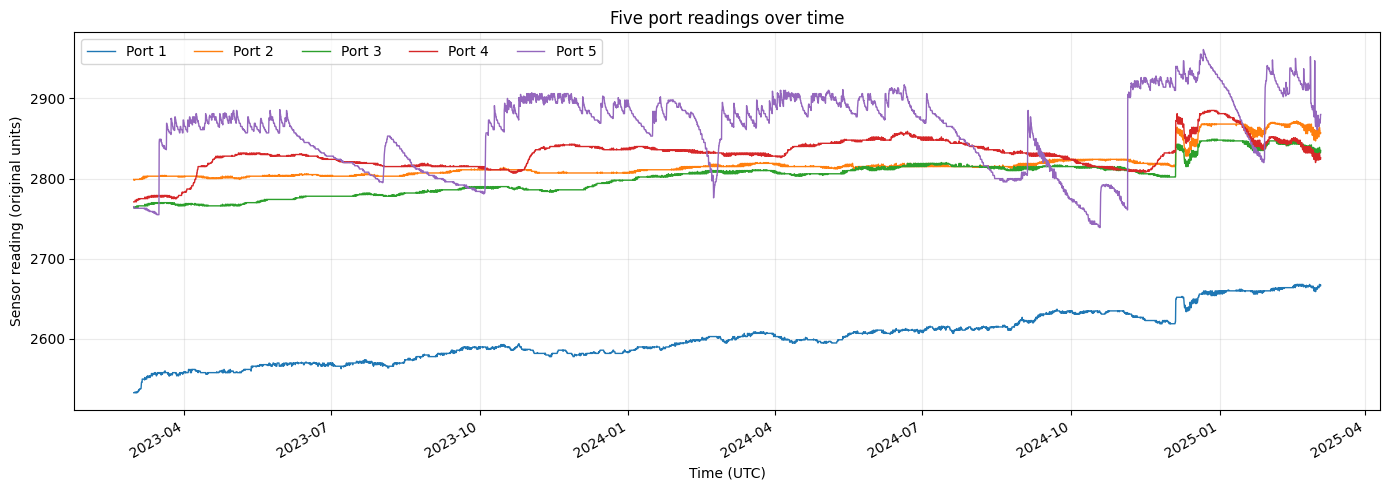

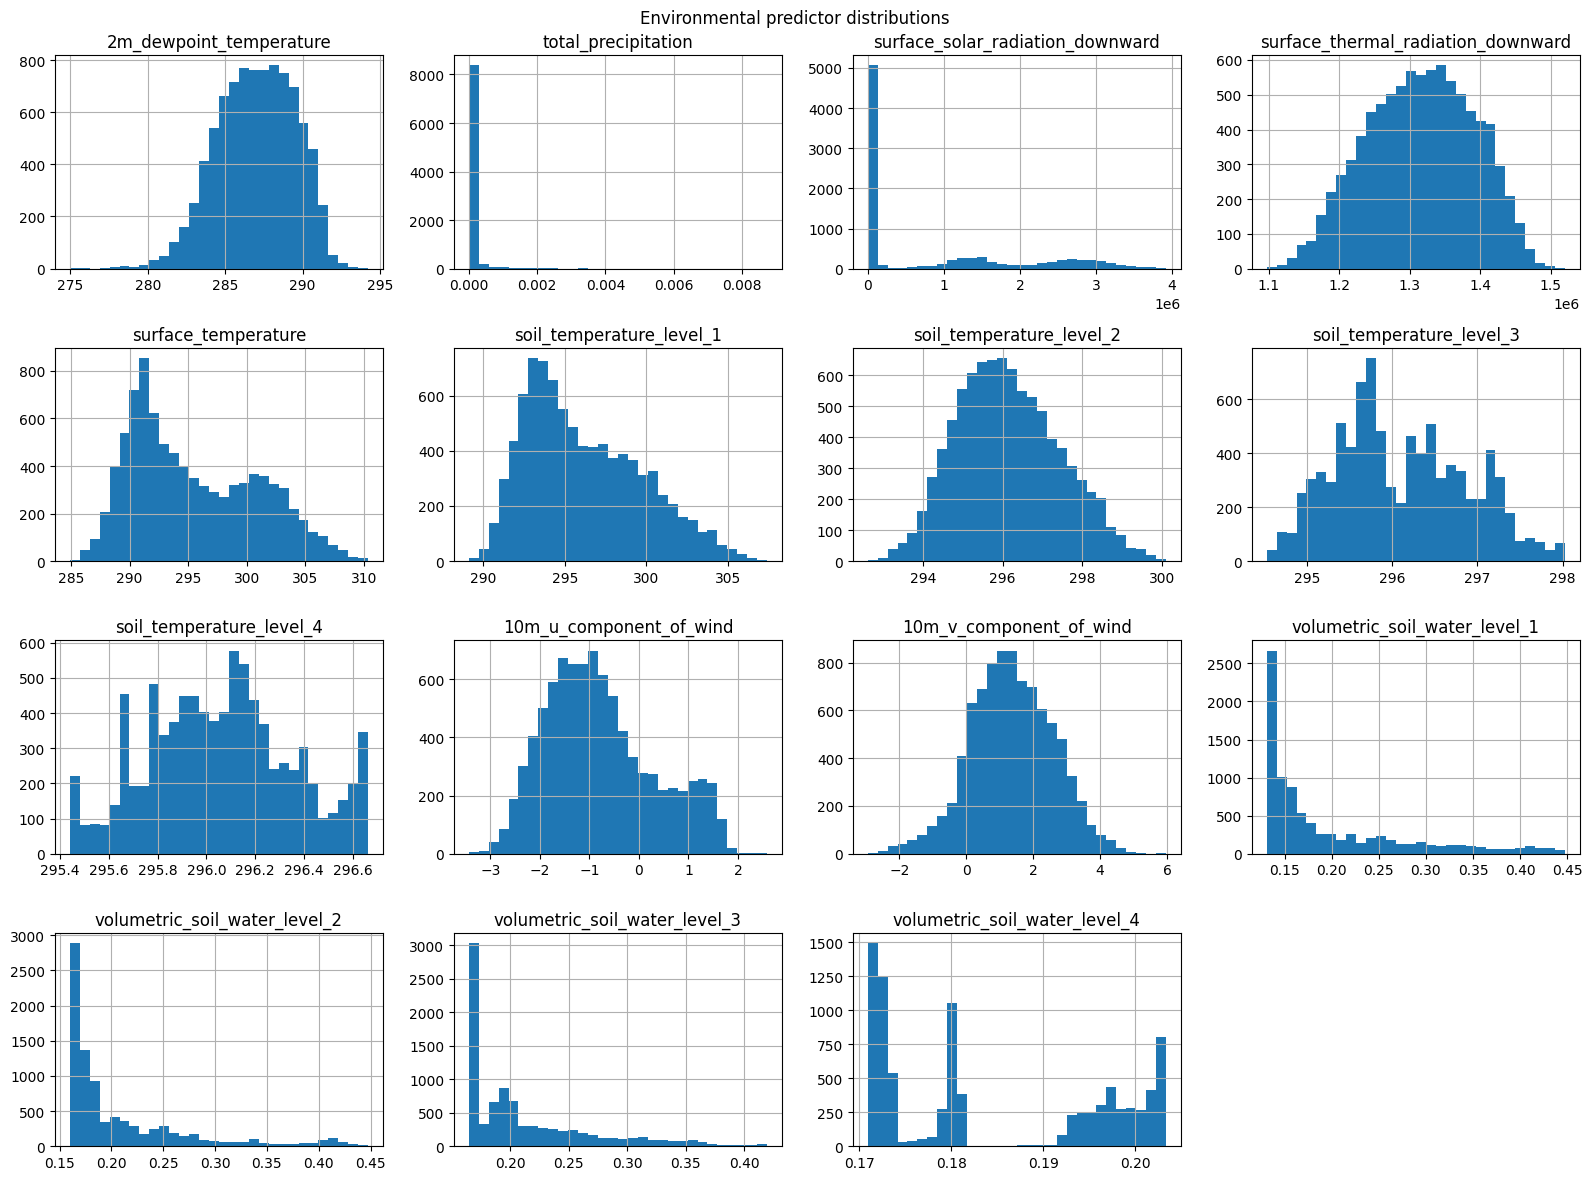

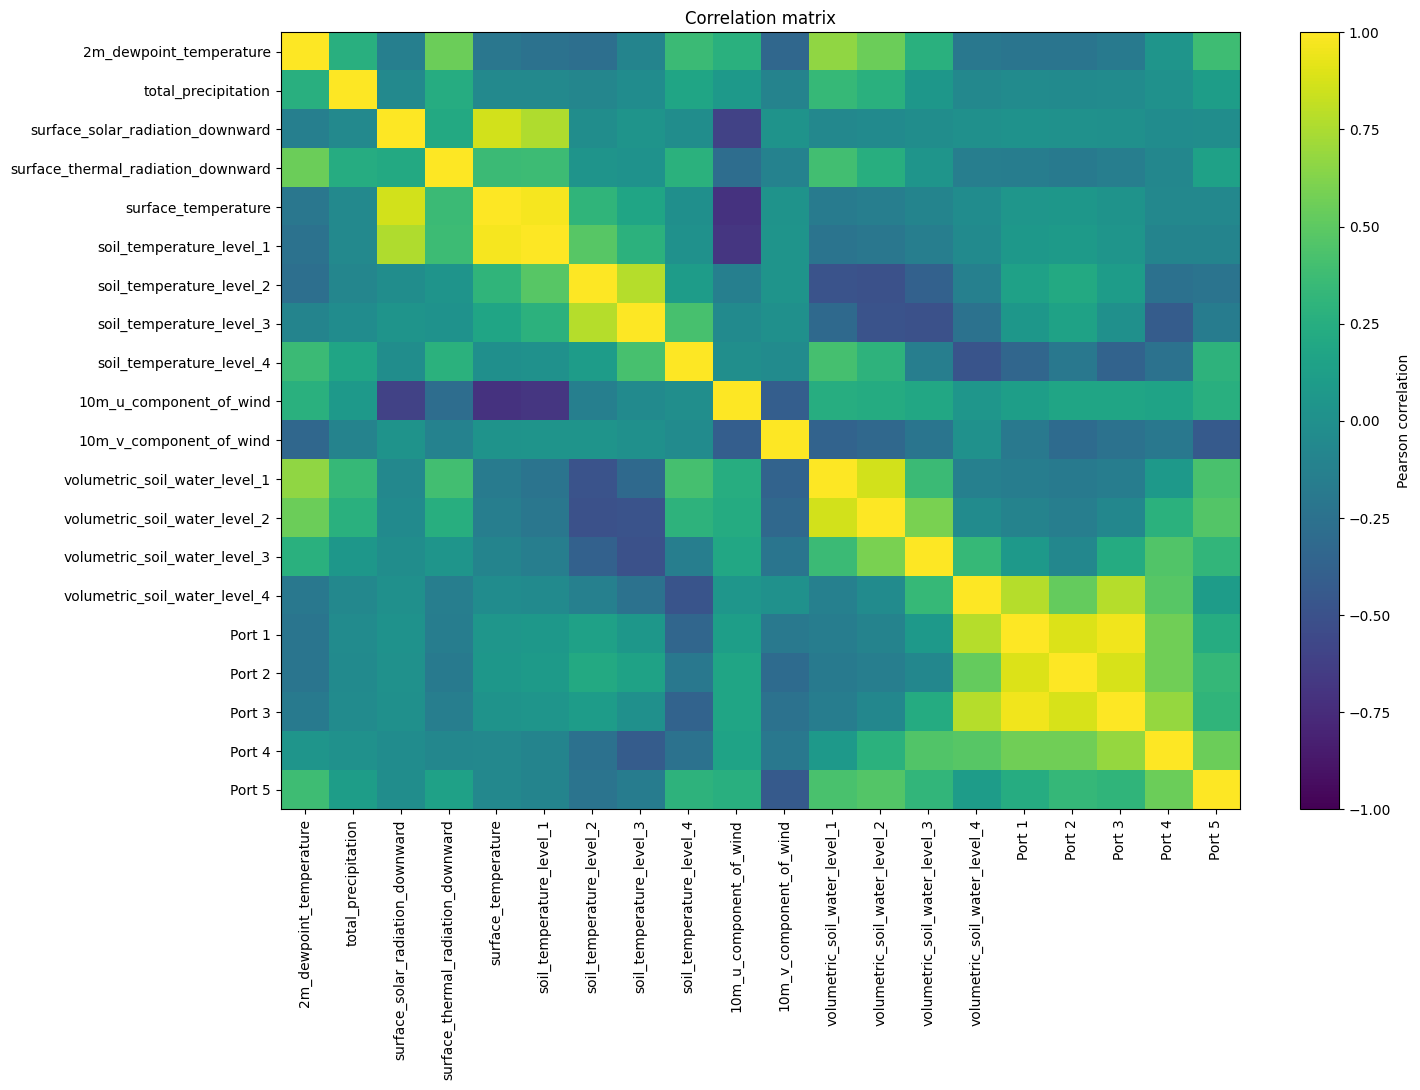

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
for target in TARGET_COLS:
    ax.plot(df[TIME_COL], df[target], label=target, linewidth=1)
ax.set_title("Five port readings over time")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Sensor reading (original units)")
ax.legend(ncol=5)
ax.grid(True, alpha=.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

df[ENVIRONMENTAL_COLS].hist(figsize=(16, 12), bins=30)
plt.suptitle("Environmental predictor distributions")
plt.tight_layout()
plt.show()

corr = df[ENVIRONMENTAL_COLS + TARGET_COLS].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(15, 11))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Correlation matrix")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

## 5. Forecast target alignment and feature engineering

In [19]:
def make_base_frame(source, horizon=1):
    out = source.copy()
    out["target_time"] = out[TIME_COL].shift(-horizon)
    for target in TARGET_COLS:
        out[f"__target__{target}"] = out[target].shift(-horizon)
    # Calendar features refer to the predictor/forecast-origin timestamp.
    ts = out[TIME_COL]
    out["calendar_hour"] = ts.dt.hour
    out["calendar_dayofweek"] = ts.dt.dayofweek
    out["calendar_month"] = ts.dt.month
    out["calendar_dayofyear"] = ts.dt.dayofyear
    out["calendar_is_weekend"] = (ts.dt.dayofweek >= 5).astype(int)
    out["calendar_hour_sin"] = np.sin(2 * np.pi * ts.dt.hour / 24)
    out["calendar_hour_cos"] = np.cos(2 * np.pi * ts.dt.hour / 24)
    out["calendar_doy_sin"] = np.sin(2 * np.pi * ts.dt.dayofyear / 365.25)
    out["calendar_doy_cos"] = np.cos(2 * np.pi * ts.dt.dayofyear / 365.25)
    # Derived environmental features.
    out["wind_speed_10m"] = np.sqrt(
        out["10m_u_component_of_wind"]**2 + out["10m_v_component_of_wind"]**2
    )
    soil_temp_cols = [f"soil_temperature_level_{i}" for i in range(1, 5)]
    soil_water_cols = [f"volumetric_soil_water_level_{i}" for i in range(1, 5)]
    out["mean_soil_temperature"] = out[soil_temp_cols].mean(axis=1)
    out["mean_volumetric_soil_water"] = out[soil_water_cols].mean(axis=1)
    out["soil_temperature_level1_minus_level4"] = (
        out["soil_temperature_level_1"] - out["soil_temperature_level_4"]
    )
    # Historical environmental features: shift first, then rolling.
    for col in ENVIRONMENTAL_COLS:
        for lag in LAG_STEPS:
            out[f"{col}__lag_{lag}"] = out[col].shift(lag)
        shifted = out[col].shift(1)
        for window in ROLLING_WINDOWS:
            out[f"{col}__rolling_mean_{window}"] = shifted.rolling(window, min_periods=window).mean()
    # Target history is an explicitly separate experiment and uses past targets only.
    for target in TARGET_COLS:
        for lag in LAG_STEPS:
            out[f"{target}__lag_{lag}"] = out[target].shift(lag)
    return out

model_frame_all = make_base_frame(df, FORECAST_HORIZON_ROWS)  # includes final rows for which future actuals are not yet observed
model_frame = model_frame_all.copy()
TARGET_INTERNAL = [f"__target__{t}" for t in TARGET_COLS]
calendar_features = [
    "calendar_hour", "calendar_dayofweek", "calendar_month", "calendar_dayofyear",
    "calendar_is_weekend", "calendar_hour_sin", "calendar_hour_cos",
    "calendar_doy_sin", "calendar_doy_cos"
]
derived_features = [
    "wind_speed_10m", "mean_soil_temperature", "mean_volumetric_soil_water",
    "soil_temperature_level1_minus_level4"
]
historical_features = [
    c for c in model_frame.columns
    if "__lag_" in c or "__rolling_mean_" in c
]
target_history_features = [c for c in historical_features if c.startswith(tuple(TARGET_COLS))]
environment_history_features = [c for c in historical_features if c not in target_history_features]

FEATURE_GROUPS = {
    "A_environmental_only": ENVIRONMENTAL_COLS,
    "B_environmental_plus_calendar": ENVIRONMENTAL_COLS + calendar_features,
    "C_environmental_plus_derived": ENVIRONMENTAL_COLS + derived_features,
    "D_environmental_calendar_history": ENVIRONMENTAL_COLS + calendar_features + derived_features + environment_history_features,
    "E_full_valid_features": ENVIRONMENTAL_COLS + calendar_features + derived_features + environment_history_features,
    "F_target_history_experiment": ENVIRONMENTAL_COLS + calendar_features + derived_features + environment_history_features + target_history_features
}
print("Forecast horizon (rows):", FORECAST_HORIZON_ROWS)
print("Engineered features:", len(calendar_features) + len(derived_features) + len(historical_features))

Forecast horizon (rows): 1
Engineered features: 103


## 6. Chronological train, validation, and test split

Rows are divided in chronological order into approximately 70% training, 15% validation, and 15% test. The validation period is used for model and feature-group selection. The test period remains untouched until the selected configuration is fixed. Rows without aligned future targets are excluded; rows with missing targets are handled explicitly for training/evaluation.

In [7]:
model_frame = model_frame.dropna(subset=["target_time"]).sort_values("target_time").reset_index(drop=True)
n = len(model_frame)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
train_df = model_frame.iloc[:train_end].copy()
val_df = model_frame.iloc[train_end:val_end].copy()
test_df = model_frame.iloc[val_end:].copy()
print("Rows after horizon alignment:", n)
print("Train:", len(train_df), train_df[TIME_COL].min(), "to", train_df[TIME_COL].max())
print("Validation:", len(val_df), val_df[TIME_COL].min(), "to", val_df[TIME_COL].max())
print("Test:", len(test_df), test_df[TIME_COL].min(), "to", test_df[TIME_COL].max())
if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError("Chronological split produced an empty partition. Check dataset size and horizon.")

def split_xy(part, features):
    X = part[features].replace([np.inf, -np.inf], np.nan)
    y = part[TARGET_INTERNAL].copy()
    return X, y

def finite_target_rows(X, y):
    mask = y.notna().all(axis=1)
    return X.loc[mask], y.loc[mask]

print("Training rows with all five targets present:",
      int(train_df[TARGET_INTERNAL].notna().all(axis=1).sum()), "/", len(train_df))
print("Validation rows with all five targets present:",
      int(val_df[TARGET_INTERNAL].notna().all(axis=1).sum()), "/", len(val_df))
print("Test rows with all five targets present:",
      int(test_df[TARGET_INTERNAL].notna().all(axis=1).sum()), "/", len(test_df))

Rows after horizon alignment: 8816
Train: 6171 2023-02-28 20:00:00+00:00 to 2024-07-27 00:00:00+00:00
Validation: 1322 2024-07-27 02:00:00+00:00 to 2024-11-14 04:00:00+00:00
Test: 1323 2024-11-14 06:00:00+00:00 to 2025-03-04 10:00:00+00:00
Training rows with all five targets present: 6171 / 6171
Validation rows with all five targets present: 1322 / 1322
Test rows with all five targets present: 1323 / 1323


## 7. Modeling helpers and candidate models

Preprocessing is contained inside each pipeline. Median imputation is fitted on training data only. Linear models use scaling; tree-based models do not. `HistGradientBoostingRegressor` is wrapped in `MultiOutputRegressor` because support for multi-output targets depends on scikit-learn estimator behavior.

In [8]:
def make_estimator(model_name):
    if model_name == "DummyRegressor":
        estimator = DummyRegressor(strategy="mean")
        scale = False
    elif model_name == "LinearRegression":
        estimator = LinearRegression()
        scale = True
    elif model_name == "Ridge":
        estimator = Ridge(alpha=1.0)
        scale = True
    elif model_name == "RandomForestRegressor":
        estimator = RandomForestRegressor(
            n_estimators=200, min_samples_leaf=2, random_state=SEED, n_jobs=-1
        )
        scale = False
    elif model_name == "ExtraTreesRegressor":
        estimator = ExtraTreesRegressor(
            n_estimators=200, min_samples_leaf=2, random_state=SEED, n_jobs=-1
        )
        scale = False
    elif model_name == "HistGradientBoostingRegressor":
        estimator = MultiOutputRegressor(
            HistGradientBoostingRegressor(max_iter=150, learning_rate=0.08, random_state=SEED)
        )
        scale = False
    else:
        raise ValueError(f"Unknown model: {model_name}")
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", estimator))
    return Pipeline(steps)

def metric_summary(y_true, y_pred, target_names=TARGET_COLS):
    rows = []
    yt = np.asarray(y_true, dtype=float)
    yp = np.asarray(y_pred, dtype=float)
    for i, name in enumerate(target_names):
        valid = np.isfinite(yt[:, i]) & np.isfinite(yp[:, i])
        if not valid.any():
            rows.append({"target": name, "n_valid": 0, "MAE": np.nan, "MSE": np.nan,
                         "RMSE": np.nan, "R2": np.nan, "explained_variance": np.nan,
                         "median_absolute_error": np.nan, "max_absolute_error": np.nan,
                         "MAPE_percent": np.nan})
            continue
        a, p = yt[valid, i], yp[valid, i]
        err = np.abs(a - p)
        mape_valid = np.abs(a) > 1e-8
        mape = 100 * np.mean(np.abs((a[mape_valid] - p[mape_valid]) / a[mape_valid])) if mape_valid.any() else np.nan
        rows.append({
            "target": name, "n_valid": int(valid.sum()),
            "MAE": mean_absolute_error(a, p),
            "MSE": mean_squared_error(a, p),
            "RMSE": mean_squared_error(a, p) ** 0.5,
            "R2": r2_score(a, p) if len(a) > 1 and np.nanstd(a) > 0 else np.nan,
            "explained_variance": explained_variance_score(a, p) if len(a) > 1 else np.nan,
            "median_absolute_error": median_absolute_error(a, p),
            "max_absolute_error": float(np.max(err)),
            "MAPE_percent": mape
        })
    return pd.DataFrame(rows)

def aggregate_metrics(per_target):
    return {
        "mean_MAE": per_target["MAE"].mean(),
        "mean_MSE": per_target["MSE"].mean(),
        "mean_RMSE": per_target["RMSE"].mean(),
        "mean_R2": per_target["R2"].mean(),
        "worst_port_by_RMSE": per_target.loc[per_target["RMSE"].idxmax(), "target"] if per_target["RMSE"].notna().any() else None,
        "best_port_by_RMSE": per_target.loc[per_target["RMSE"].idxmin(), "target"] if per_target["RMSE"].notna().any() else None
    }

## 8. Compare candidate models and feature groups

All candidates use identical chronological partitions. Failed fits or predictions are retained in the comparison output with an error description. The primary selection criterion is mean validation RMSE across the five targets.

In [9]:
MODEL_NAMES = [
    "DummyRegressor", "LinearRegression", "Ridge",
    "RandomForestRegressor", "ExtraTreesRegressor", "HistGradientBoostingRegressor"
]
comparison_rows = []
fitted_candidates = {}
validation_predictions = {}

for group_name, features in FEATURE_GROUPS.items():
    features = list(dict.fromkeys(features))
    for model_name in MODEL_NAMES:
        record = {
            "model": model_name, "feature_configuration": group_name,
            "feature_count": len(features), "training_observations": 0,
            "training_seconds": np.nan, "validation_seconds": np.nan,
            "mean_validation_RMSE": np.nan, "mean_validation_MAE": np.nan,
            "mean_validation_R2": np.nan, "error": ""
        }
        try:
            X_train, y_train = split_xy(train_df, features)
            X_train, y_train = finite_target_rows(X_train, y_train)
            X_val, y_val = split_xy(val_df, features)
            X_val, y_val = finite_target_rows(X_val, y_val)
            if len(X_train) < 5 or len(X_val) == 0:
                raise ValueError("Insufficient complete-target training or validation rows.")
            pipe = make_estimator(model_name)
            t0 = time.perf_counter()
            pipe.fit(X_train, y_train)
            record["training_seconds"] = time.perf_counter() - t0
            t1 = time.perf_counter()
            pred = pipe.predict(X_val)
            record["validation_seconds"] = time.perf_counter() - t1
            per_target = metric_summary(y_val, pred)
            agg = aggregate_metrics(per_target)
            record["training_observations"] = len(X_train)
            record["mean_validation_RMSE"] = agg["mean_RMSE"]
            record["mean_validation_MAE"] = agg["mean_MAE"]
            record["mean_validation_R2"] = agg["mean_R2"]
            record["per_target_validation_metrics"] = per_target.to_dict(orient="records")
            key = (model_name, group_name)
            fitted_candidates[key] = pipe
            validation_predictions[key] = (X_val, y_val, pred, per_target)
        except Exception as exc:
            record["error"] = f"{type(exc).__name__}: {exc}"
            print("FAILED:", model_name, group_name, "->", record["error"])
        comparison_rows.append(record)

comparison = pd.DataFrame(comparison_rows)
display(comparison[[
    "model", "feature_configuration", "feature_count", "training_observations",
    "training_seconds", "validation_seconds", "mean_validation_RMSE",
    "mean_validation_MAE", "mean_validation_R2", "error"
]].sort_values("mean_validation_RMSE"))
comparison.to_csv(COMPARISON_PATH, index=False)
valid_comparison = comparison.dropna(subset=["mean_validation_RMSE"])
if valid_comparison.empty:
    raise RuntimeError("Every candidate model failed. Review the error column in the comparison table.")
best_row = valid_comparison.sort_values("mean_validation_RMSE").iloc[0]
selected_model_name = best_row["model"]
selected_group_name = best_row["feature_configuration"]
selected_features = list(dict.fromkeys(FEATURE_GROUPS[selected_group_name]))
print("Selected on validation only:", selected_model_name, "|", selected_group_name)

,model,feature_configuration,feature_count,training_observations,training_seconds,validation_seconds,mean_validation_RMSE,mean_validation_MAE,mean_validation_R2,error
31,LinearRegression,F_target_history_experiment,118,6171,0.137578,0.008034,1.966891,0.969145,0.952563,
32,Ridge,F_target_history_experiment,118,6171,0.096861,0.008648,1.986186,0.995813,0.949122,
35,HistGradientBoostingRegressor,F_target_history_experiment,118,6171,37.662295,0.130684,8.597745,6.206263,-0.141630,
34,ExtraTreesRegressor,F_target_history_experiment,118,6171,15.087821,0.317006,18.641892,15.513169,-14.201783,
21,RandomForestRegressor,D_environmental_calendar_history,103,6171,57.033191,3.623541,19.863665,16.835486,-2.311056,
27,RandomForestRegressor,E_full_valid_features,103,6171,62.008868,0.126733,19.863665,16.835486,-2.311056,
3,RandomForestRegressor,A_environmental_only,15,6171,7.791686,0.078519,19.980750,16.965150,-2.337323,
19,LinearRegression,D_environmental_calendar_history,103,6171,0.123543,0.006290,20.216043,18.025115,-2.000135,
25,LinearRegression,E_full_valid_features,103,6171,0.131773,0.014007,20.216043,18.025115,-2.000135,
15,RandomForestRegressor,C_environmental_plus_derived,19,6171,10.045434,0.084277,20.235536,17.268256,-2.422673,


Selected on validation only: LinearRegression | F_target_history_experiment


## 9. Optional chronological hyperparameter tuning

A small grid is evaluated using expanding-window `TimeSeriesSplit` on the training partition only. 

In [10]:
def rmse_multi(y_true, y_pred):
    per = metric_summary(y_true, y_pred)
    return float(per["RMSE"].mean())

X_train_selected, y_train_selected = split_xy(train_df, selected_features)
X_train_selected, y_train_selected = finite_target_rows(X_train_selected, y_train_selected)

tuning_results = []
best_tuned_pipeline = None
best_tuned_score = np.inf
best_tuned_params = {}

if selected_model_name in {"Ridge", "RandomForestRegressor", "ExtraTreesRegressor"} and len(X_train_selected) >= 20:
    if selected_model_name == "Ridge":
        grid = [{"model__alpha": a} for a in [0.1, 1.0, 10.0, 100.0]]
    else:
        grid = []
        for n_estimators in [100, 200]:
            for max_depth in [None, 12]:
                for min_samples_leaf in [1, 3]:
                    grid.append({
                        "model__n_estimators": [n_estimators],
                        "model__max_depth": [max_depth],
                        "model__min_samples_leaf": [min_samples_leaf]
                    })
        grid = list(ParameterGrid({"model__n_estimators": [100, 200],
                                   "model__max_depth": [None, 12],
                                   "model__min_samples_leaf": [1, 3]}))
    n_splits = min(4, max(2, len(X_train_selected) // 10))
    tscv = TimeSeriesSplit(n_splits=n_splits)
    for params in grid:
        fold_scores = []
        try:
            for tr_idx, va_idx in tscv.split(X_train_selected):
                Xtr, Xva = X_train_selected.iloc[tr_idx], X_train_selected.iloc[va_idx]
                ytr, yva = y_train_selected.iloc[tr_idx], y_train_selected.iloc[va_idx]
                candidate = make_estimator(selected_model_name).set_params(**params)
                candidate.fit(Xtr, ytr)
                fold_scores.append(rmse_multi(yva, candidate.predict(Xva)))
            score = float(np.mean(fold_scores))
            tuning_results.append({"model": selected_model_name, "params": params,
                                   "mean_cv_RMSE": score, "fold_scores": fold_scores, "error": ""})
            if score < best_tuned_score:
                best_tuned_score, best_tuned_params = score, params
        except Exception as exc:
            tuning_results.append({"model": selected_model_name, "params": params,
                                   "mean_cv_RMSE": np.nan, "fold_scores": fold_scores,
                                   "error": f"{type(exc).__name__}: {exc}"})
    display(pd.DataFrame(tuning_results))
else:
    print("Tuning skipped: selected model is not in the configured tuning set or training sample is too small.")

print("Best training-only CV parameters:", best_tuned_params or "No tuning parameters selected")
print("Best training-only CV mean RMSE:", best_tuned_score if np.isfinite(best_tuned_score) else "not available")

Tuning skipped: selected model is not in the configured tuning set or training sample is too small.
Best training-only CV parameters: No tuning parameters selected
Best training-only CV mean RMSE: not available


## 10. Fiting the selected pipeline and evaluate validation, then test

After choosing the feature group and estimator on validation results, we refit using training plus validation data and evaluate once on the held-out test period. Hyperparameters are only applied when a tuning run produced a valid result. The test set is not used for model selection.

In [11]:
final_params = best_tuned_params if best_tuned_params else {}
final_pipeline = make_estimator(selected_model_name)
if final_params:
    final_pipeline.set_params(**final_params)

trainval_df = pd.concat([train_df, val_df], axis=0).sort_values(TIME_COL)
X_trainval, y_trainval = split_xy(trainval_df, selected_features)
X_trainval, y_trainval = finite_target_rows(X_trainval, y_trainval)
X_val, y_val = split_xy(val_df, selected_features)
X_val, y_val = finite_target_rows(X_val, y_val)
X_test, y_test = split_xy(test_df, selected_features)
X_test, y_test = finite_target_rows(X_test, y_test)

final_pipeline.fit(X_trainval, y_trainval)
val_pred_final = final_pipeline.predict(X_val)
test_pred = final_pipeline.predict(X_test)

validation_metrics = metric_summary(y_val, val_pred_final)
test_metrics = metric_summary(y_test, test_pred)
print("Validation metrics:")
display(validation_metrics)
print("Test metrics:")
display(test_metrics)
print("Aggregate test metrics:", aggregate_metrics(test_metrics))

dummy = make_estimator("DummyRegressor")
dummy.fit(X_trainval, y_trainval)
dummy_test_metrics = metric_summary(y_test, dummy.predict(X_test))
print("Dummy baseline test metrics:")
display(dummy_test_metrics)
print("Selected model vs dummy mean RMSE:",
      test_metrics["RMSE"].mean(), "vs", dummy_test_metrics["RMSE"].mean())

Validation metrics:


,target,n_valid,MAE,MSE,RMSE,R2,explained_variance,median_absolute_error,max_absolute_error,MAPE_percent
0,Port 1,1322,0.544403,0.563584,0.750722,0.992376,0.992395,0.381013,3.377192,0.020734
1,Port 2,1322,0.480229,0.400301,0.632694,0.972512,0.972513,0.383152,2.838264,0.017030
2,Port 3,1322,0.564084,0.551277,0.742481,0.880988,0.880996,0.459682,4.136123,0.020051
3,Port 4,1322,0.554751,0.514217,0.717089,0.994996,0.994996,0.453526,2.885454,0.019633
4,Port 5,1322,1.897532,38.252180,6.184835,0.979241,0.979242,1.057792,140.238452,0.067134


Test metrics:


,target,n_valid,MAE,MSE,RMSE,R2,explained_variance,median_absolute_error,max_absolute_error,MAPE_percent
0,Port 1,1323,2.059226,7.117053,2.667781,0.970968,0.982643,2.049011,27.872383,0.077519
1,Port 2,1323,7.444259,74.750606,8.645843,0.793275,0.941647,9.289704,39.344098,0.259981
2,Port 3,1323,1.176749,4.479897,2.116577,0.982202,0.982209,0.677720,36.437717,0.041503
3,Port 4,1323,1.694693,6.401746,2.530167,0.985862,0.988607,1.333296,36.313973,0.059326
4,Port 5,1323,3.387655,36.192379,6.016010,0.963855,0.970731,2.523210,68.648621,0.116336


Aggregate test metrics: {'mean_MAE': np.float64(3.1525163103178193), 'mean_MSE': np.float64(25.788336211765873), 'mean_RMSE': np.float64(4.395275586184285), 'mean_R2': np.float64(0.939232518696369), 'worst_port_by_RMSE': 'Port 2', 'best_port_by_RMSE': 'Port 3'}
Dummy baseline test metrics:


,target,n_valid,MAE,MSE,RMSE,R2,explained_variance,median_absolute_error,max_absolute_error,MAPE_percent
0,Port 1,1323,60.100637,3857.232752,62.106624,-14.734418,0.000000e+00,68.201922,76.201922,2.262894
1,Port 2,1323,42.626662,2178.627203,46.675767,-5.025050,1.110223e-16,52.021220,61.021220,1.489376
2,Port 3,1323,38.934106,1767.574524,42.042532,-6.022268,2.220446e-16,45.665021,53.665021,1.370581
3,Port 4,1323,26.237627,1005.209194,31.705034,-1.220005,-2.220446e-16,20.967570,57.967570,0.916213
4,Port 5,1323,60.129322,4228.866104,65.029732,-3.223294,0.000000e+00,66.624049,108.624049,2.058315


Selected model vs dummy mean RMSE: 4.395275586184285 vs 49.51193796121966


## 11. Actual-versus-predicted and residual diagnostics

Residual convention for diagnostics is `Actual - Predicted`. The exported CSV uses the separately specified convention `Predicted - Actual`. Plots are produced for each port, with test-period time series, scatter plot with a 45-degree reference line, residual series, residual histogram, and absolute-error distribution.

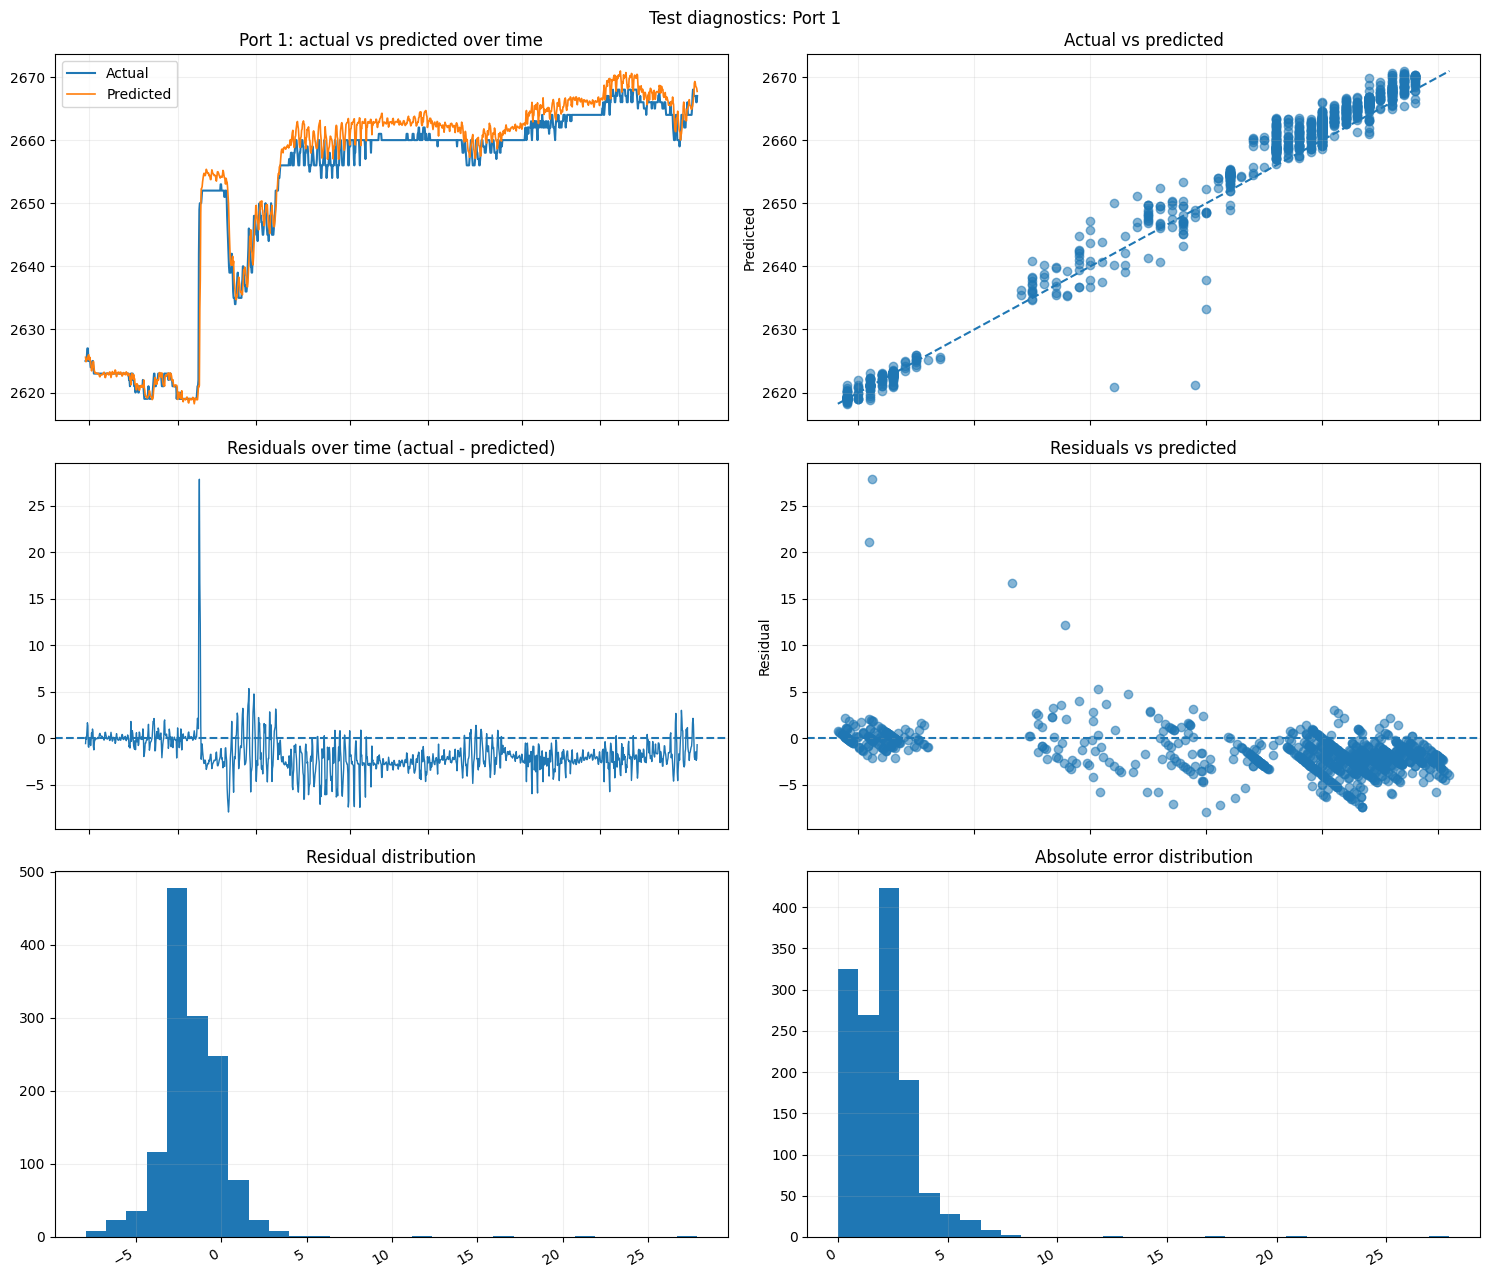

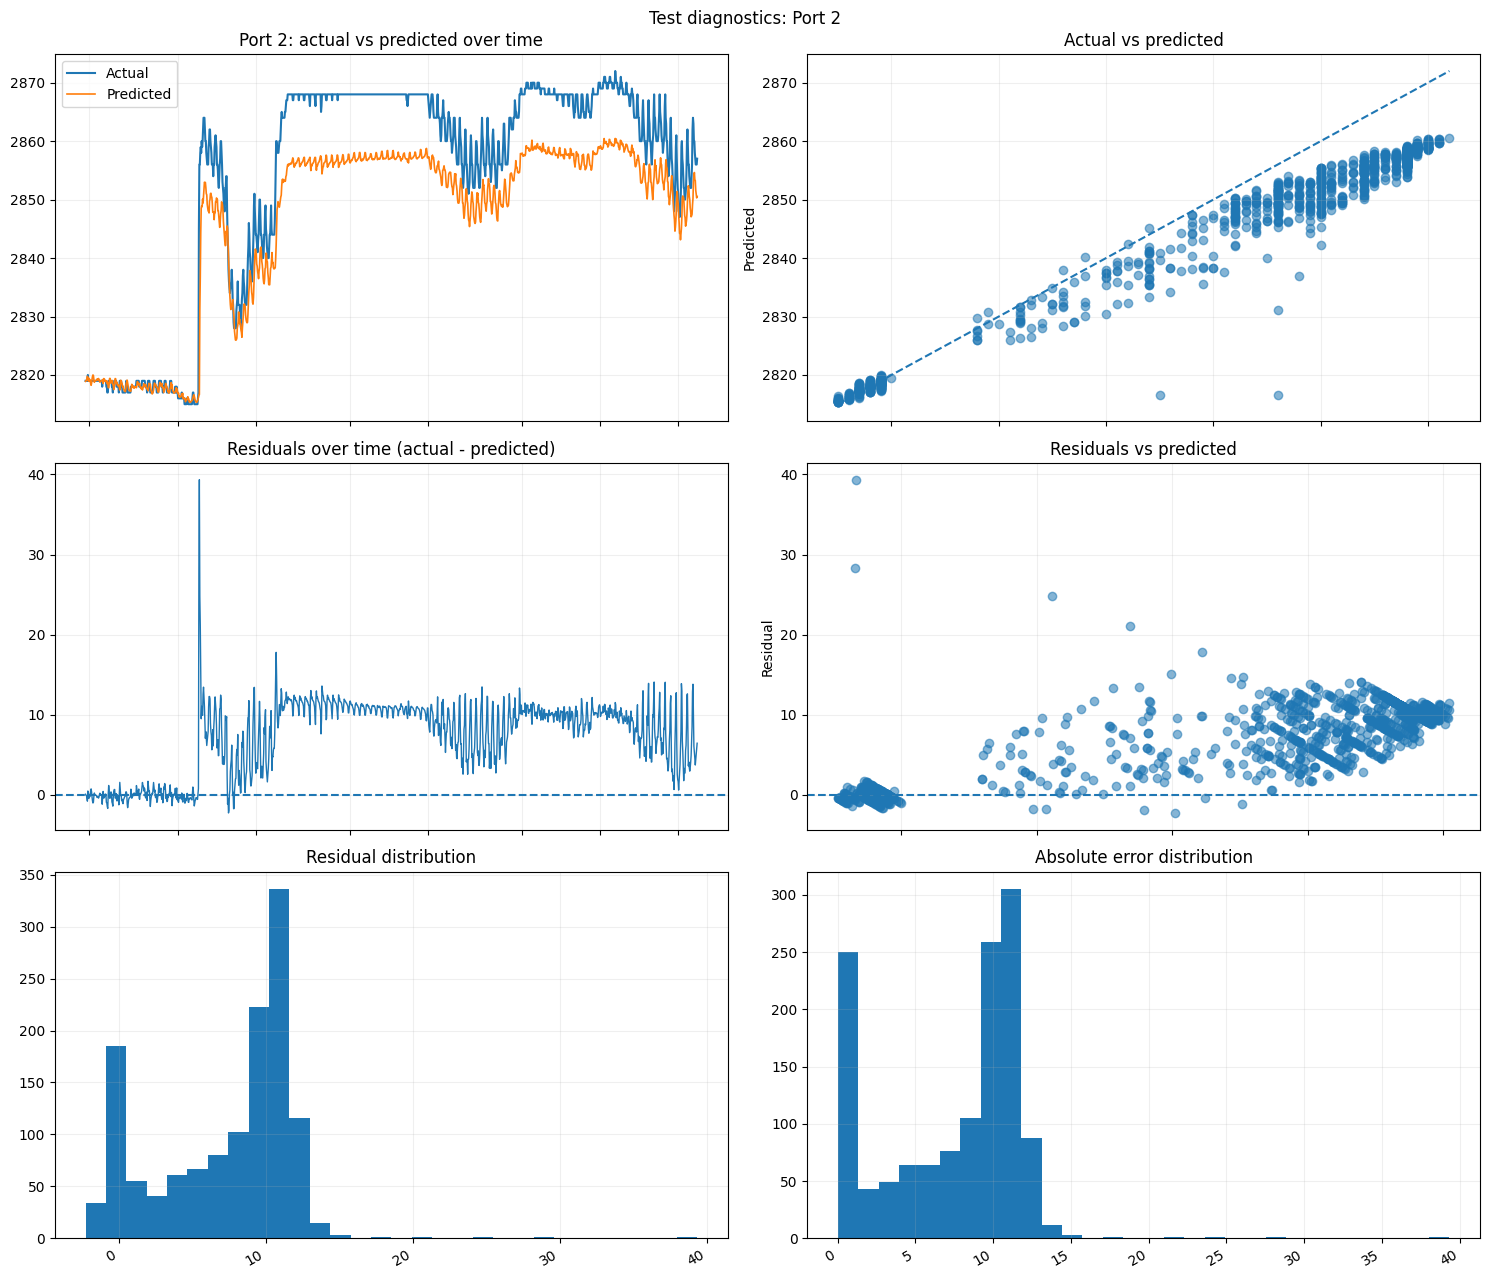

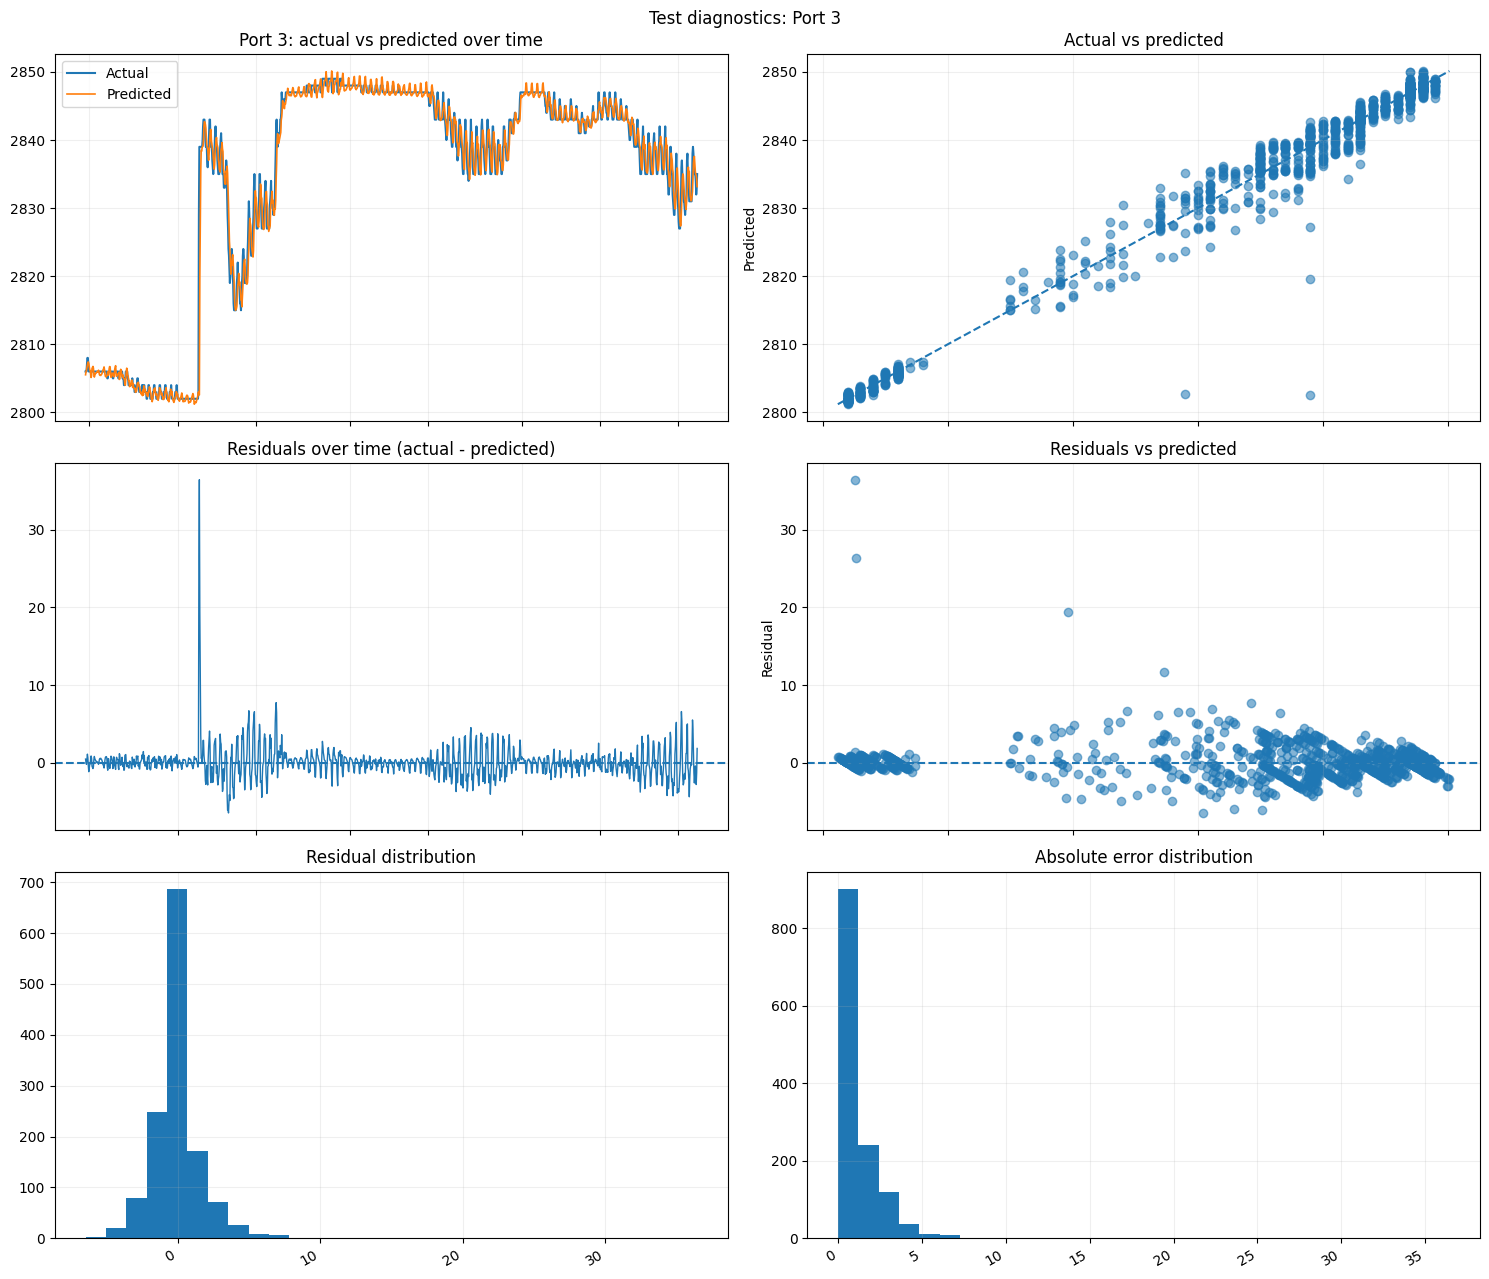

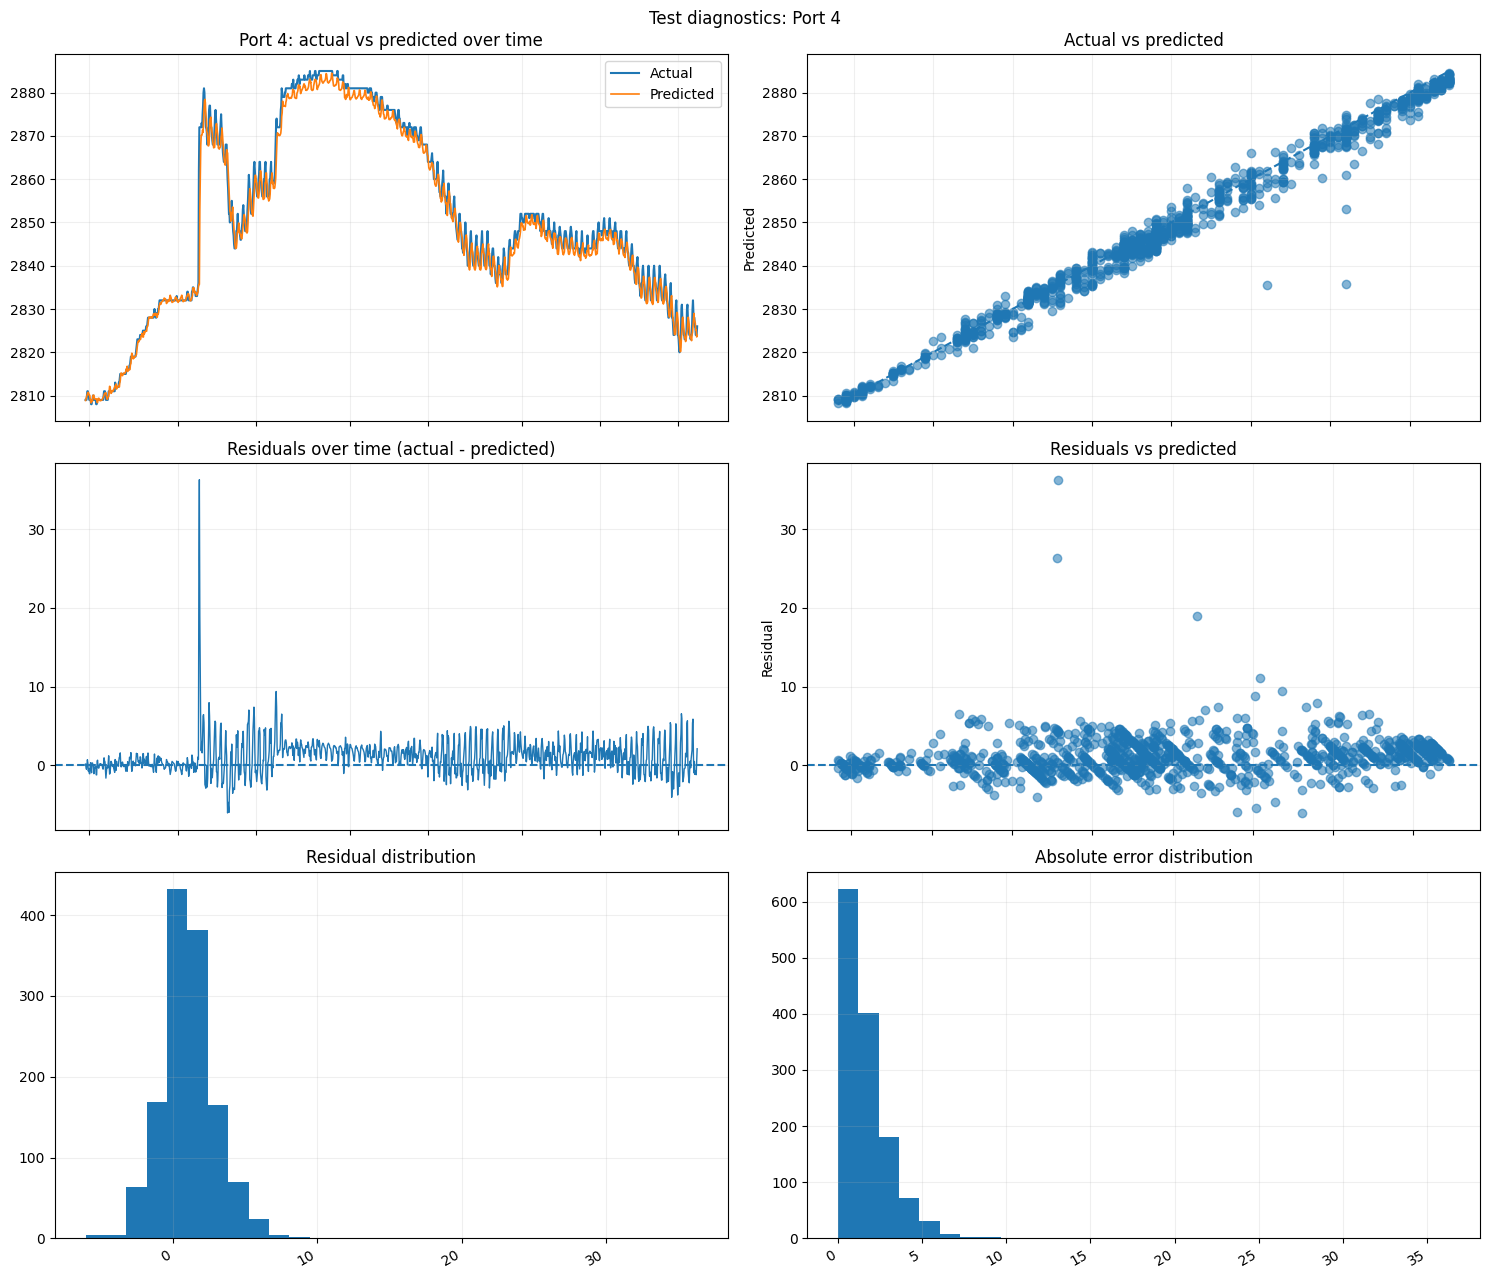

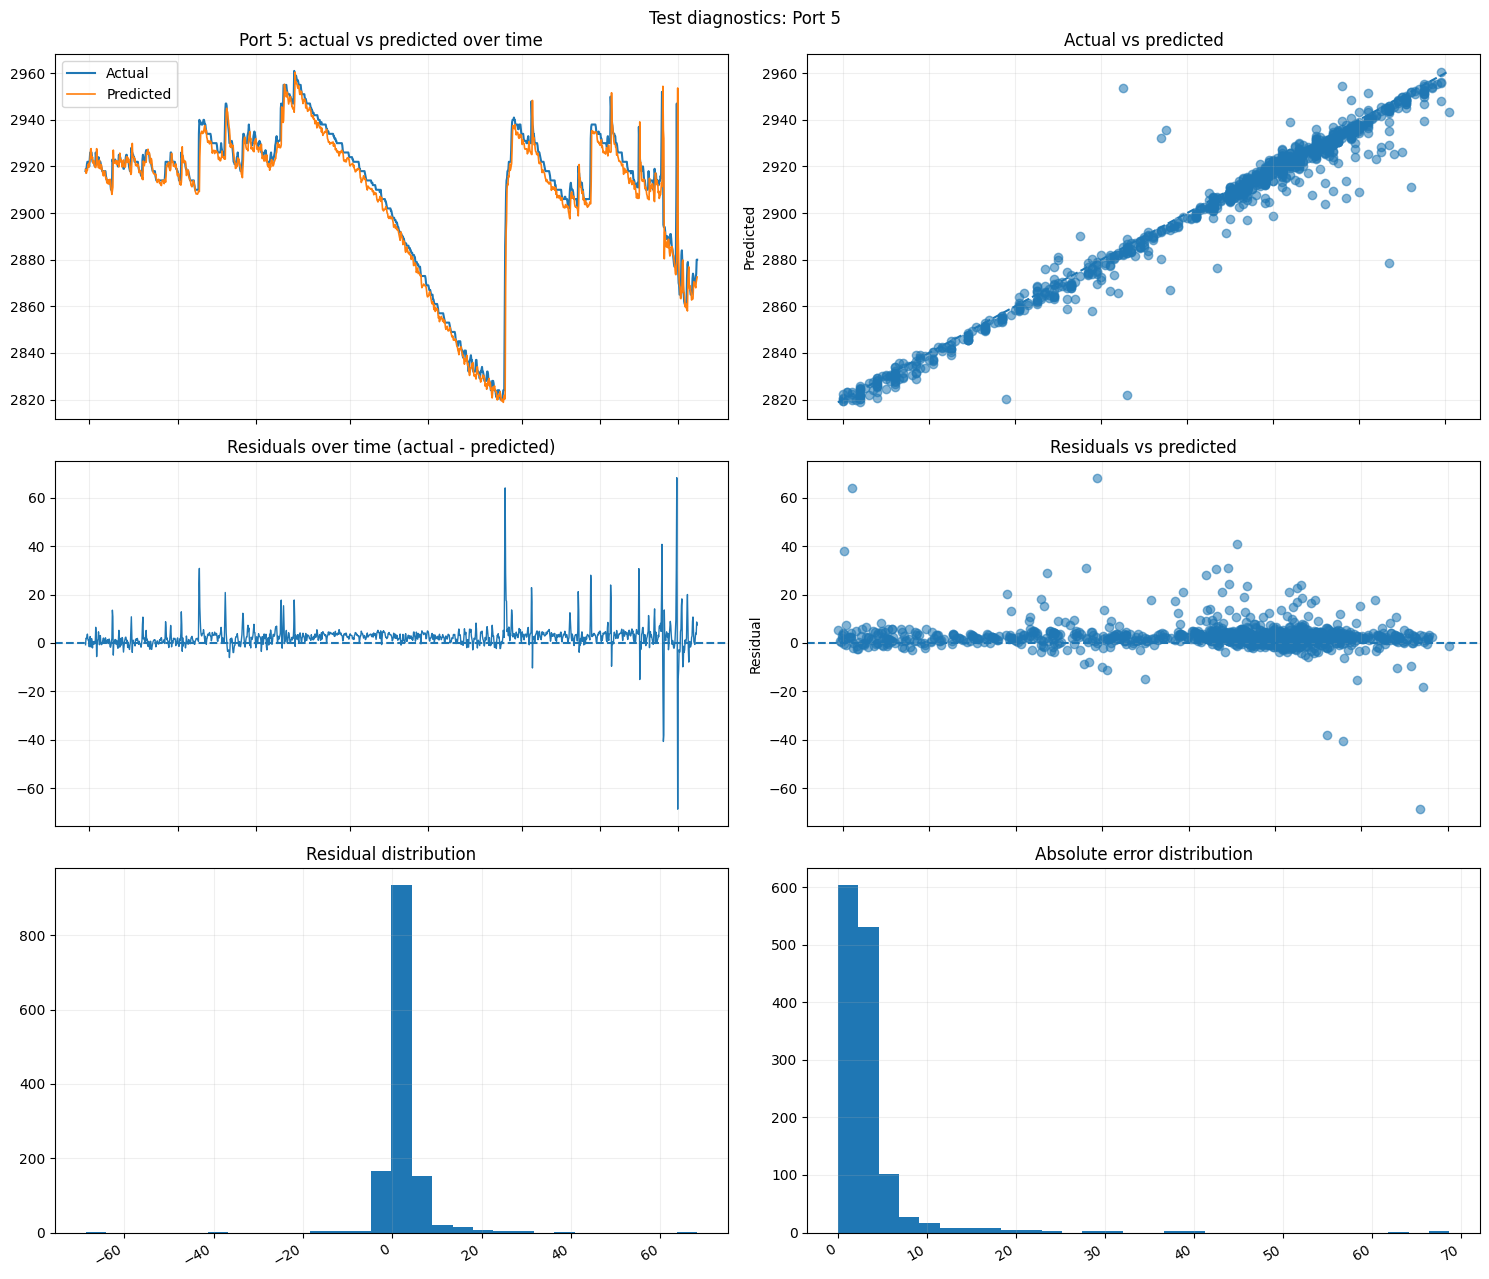

,target,mean_residual,median_residual,residual_std,minimum_residual,maximum_residual,lag1_residual_autocorrelation
0,Port 1,-1.691790,-1.986736,2.063521,-7.964932,27.872383,0.797896
1,Port 2,7.324643,9.289704,4.595233,-2.242176,39.344098,0.934699
2,Port 3,0.042121,0.018291,2.116958,-6.460580,36.437717,0.737523
3,Port 4,1.114936,0.963732,2.272128,-6.072391,36.313973,0.734925
4,Port 5,2.623831,2.338742,5.415723,-68.648621,68.242584,0.501541


In [12]:
test_times = test_df.loc[y_test.index, "target_time"].reset_index(drop=True)
y_true_arr = np.asarray(y_test, dtype=float)
y_pred_arr = np.asarray(test_pred, dtype=float)
residuals = y_true_arr - y_pred_arr

for i, target in enumerate(TARGET_COLS):
    actual = y_true_arr[:, i]
    predicted = y_pred_arr[:, i]
    resid = actual - predicted
    valid = np.isfinite(actual) & np.isfinite(predicted)
    fig, axes = plt.subplots(3, 2, figsize=(15, 13))
    axes[0,0].plot(test_times, actual, label="Actual", linewidth=1.5)
    axes[0,0].plot(test_times, predicted, label="Predicted", linewidth=1.2)
    axes[0,0].set_title(f"{target}: actual vs predicted over time")
    axes[0,0].legend()
    axes[0,1].scatter(actual[valid], predicted[valid], alpha=.55)
    if valid.any():
        lo = min(actual[valid].min(), predicted[valid].min())
        hi = max(actual[valid].max(), predicted[valid].max())
        axes[0,1].plot([lo, hi], [lo, hi], linestyle="--")
    axes[0,1].set_title("Actual vs predicted")
    axes[0,1].set_xlabel("Actual"); axes[0,1].set_ylabel("Predicted")
    axes[1,0].plot(test_times, resid, linewidth=1)
    axes[1,0].axhline(0, linestyle="--")
    axes[1,0].set_title("Residuals over time (actual - predicted)")
    axes[1,1].scatter(predicted[valid], resid[valid], alpha=.55)
    axes[1,1].axhline(0, linestyle="--")
    axes[1,1].set_title("Residuals vs predicted")
    axes[1,1].set_xlabel("Predicted"); axes[1,1].set_ylabel("Residual")
    axes[2,0].hist(resid[valid], bins=30)
    axes[2,0].set_title("Residual distribution")
    axes[2,1].hist(np.abs(resid[valid]), bins=30)
    axes[2,1].set_title("Absolute error distribution")
    for ax in axes.flat:
        ax.grid(True, alpha=.2)
    fig.suptitle(f"Test diagnostics: {target}")
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

residual_summary = []
for i, target in enumerate(TARGET_COLS):
    r = residuals[:, i]
    r = r[np.isfinite(r)]
    residual_summary.append({
        "target": target, "mean_residual": np.mean(r) if len(r) else np.nan,
        "median_residual": np.median(r) if len(r) else np.nan,
        "residual_std": np.std(r, ddof=1) if len(r) > 1 else np.nan,
        "minimum_residual": np.min(r) if len(r) else np.nan,
        "maximum_residual": np.max(r) if len(r) else np.nan,
        "lag1_residual_autocorrelation": pd.Series(r).autocorr(lag=1) if len(r) > 2 else np.nan
    })
display(pd.DataFrame(residual_summary))

## 12. Feature importance and interpretation

Permutation importance is computed on the validation partition using mean multi-output RMSE as the scoring objective. It estimates predictive contribution, not causation. It can be computationally expensive for large datasets; reduce `n_repeats` if necessary.

In [13]:
def neg_mean_rmse_scorer(estimator, X, y):
    return -rmse_multi(y, estimator.predict(X))

X_val_imp, y_val_imp = split_xy(val_df, selected_features)
X_val_imp, y_val_imp = finite_target_rows(X_val_imp, y_val_imp)
importance_rows = []
try:
    perm = permutation_importance(
        final_pipeline, X_val_imp, y_val_imp,
        scoring=neg_mean_rmse_scorer, n_repeats=5,
        random_state=SEED, n_jobs=-1
    )
    for feature, mean_imp, std_imp in zip(selected_features, perm.importances_mean, perm.importances_std):
        importance_rows.append({
            "feature_name": feature, "importance_value": float(mean_imp),
            "importance_std": float(std_imp), "target_or_aggregation": "multi-output mean RMSE"
        })
except Exception as exc:
    print("Permutation importance failed:", type(exc).__name__, str(exc))
    # Keep an explicit artifact describing the failure rather than implying importance was calculated.
    importance_rows.append({
        "feature_name": "", "importance_value": np.nan, "importance_std": np.nan,
        "target_or_aggregation": f"FAILED: {type(exc).__name__}: {exc}"
    })
importance_df = pd.DataFrame(importance_rows)
importance_df.to_csv(IMPORTANCE_PATH, index=False)
display(importance_df.sort_values("importance_value", ascending=False).head(25))

,feature_name,importance_value,importance_std,target_or_aggregation
41,surface_solar_radiation_downward__rolling_mean_3,240.384489,2.523661,multi-output mean RMSE
38,surface_solar_radiation_downward__lag_1,91.855206,0.896585,multi-output mean RMSE
40,surface_solar_radiation_downward__lag_3,91.735796,0.546168,multi-output mean RMSE
39,surface_solar_radiation_downward__lag_2,91.540592,1.304884,multi-output mean RMSE
56,soil_temperature_level_1__rolling_mean_3,70.083455,0.849541,multi-output mean RMSE
51,surface_temperature__rolling_mean_3,56.057921,0.569596,multi-output mean RMSE
61,soil_temperature_level_2__rolling_mean_3,52.509229,0.988138,multi-output mean RMSE
65,soil_temperature_level_3__lag_3,30.057491,0.122144,multi-output mean RMSE
54,soil_temperature_level_1__lag_2,26.286943,0.316721,multi-output mean RMSE
53,soil_temperature_level_1__lag_1,25.701432,0.292623,multi-output mean RMSE


## 13.The exact 19-column prediction CSV

Predictions are generated for rows with valid feature construction, including rows without observed future targets where possible. The CSV has exactly the requested columns and order. Actual values remain missing when not observed; they are never replaced with predictions. Error is `Predicted - Actual`.

In [20]:
# Predict every row where features can be constructed, including the final horizon rows.
# Actual targets for those final rows remain missing because the future observation is not yet available.
X_all = model_frame_all[selected_features].replace([np.inf, -np.inf], np.nan)
all_predictions = final_pipeline.predict(X_all)
output_times = model_frame_all["target_time"].copy()
if output_times.isna().any():
    # Estimate only the output timestamp from the median observed interval; this does not create actual target data.
    median_interval = df[TIME_COL].diff().dropna().median()
    if pd.isna(median_interval):
        raise ValueError("Cannot infer a future output timestamp: no usable timestamp interval.")
    missing_time_mask = output_times.isna()
    output_times.loc[missing_time_mask] = (
        model_frame_all.loc[missing_time_mask, TIME_COL]
        + median_interval * FORECAST_HORIZON_ROWS
    )
pred_frame = pd.DataFrame({"valid_time": output_times.values})
for i, target in enumerate(TARGET_COLS):
    pred_frame[f"Actual {target}"] = model_frame_all[TARGET_INTERNAL[i]].to_numpy()
    pred_frame[f"Predicted {target}"] = all_predictions[:, i]
    pred_frame[f"{target} Error"] = pred_frame[f"Predicted {target}"] - pred_frame[f"Actual {target}"]

pred_cols = [f"Predicted {t}" for t in TARGET_COLS]
actual_cols = [f"Actual {t}" for t in TARGET_COLS]
error_cols = [f"{t} Error" for t in TARGET_COLS]
pred_frame["Average Predicted"] = pred_frame[pred_cols].mean(axis=1, skipna=True)
pred_frame["Average Actual"] = pred_frame[actual_cols].mean(axis=1, skipna=True)
pred_frame["Average Error"] = pred_frame["Average Predicted"] - pred_frame["Average Actual"]
pred_frame = pred_frame[PREDICTION_COLUMNS]

assert list(pred_frame.columns) == PREDICTION_COLUMNS
assert len(pred_frame.columns) == 19
for col in [c for c in pred_frame.columns if c != "valid_time"]:
    pred_frame[col] = pd.to_numeric(pred_frame[col], errors="coerce")
pred_frame["valid_time"] = pd.to_datetime(pred_frame["valid_time"], utc=True, errors="coerce")
if pred_frame["valid_time"].duplicated().any():
    raise ValueError("Duplicate output timestamps detected. Investigate source timestamp duplicates/alignment.")
# Validate error arithmetic where actuals are available.
for target in TARGET_COLS:
    expected_error = pred_frame[f"Predicted {target}"] - pred_frame[f"Actual {target}"]
    assert np.allclose(pred_frame[f"{target} Error"], expected_error, equal_nan=True)
assert np.allclose(
    pred_frame["Average Error"],
    pred_frame["Average Predicted"] - pred_frame["Average Actual"],
    equal_nan=True
)
pred_frame.to_csv(PREDICTION_PATH, index=False, date_format="%Y-%m-%dT%H:%M:%SZ")



In [21]:
print("First five rows:")
display(pred_frame.head())


First five rows:


,valid_time,Actual Port 1,Predicted Port 1,Port 1 Error,Actual Port 2,Predicted Port 2,Port 2 Error,Actual Port 3,Predicted Port 3,Port 3 Error,Actual Port 4,Predicted Port 4,Port 4 Error,Actual Port 5,Predicted Port 5,Port 5 Error,Average Predicted,Average Actual,Average Error
0,2023-02-28 22:00:00+00:00,2533.0,2533.000000,3.183231e-12,2799.0,2799.000000,1.818989e-12,2764.0,2764.000000,-4.547474e-13,2771.0,2771.000000,1.818989e-12,2764.0,2764.000000,-4.047251e-11,2726.200000,2726.2,-6.366463e-12
1,2023-03-01 00:00:00+00:00,2533.0,2533.000000,-6.821210e-12,2798.0,2798.000000,-5.002221e-12,2764.0,2764.000000,1.818989e-12,2771.0,2771.000000,-3.637979e-12,2763.0,2763.000000,7.366907e-11,2725.800000,2725.8,1.136868e-11
2,2023-03-01 02:00:00+00:00,2533.0,2533.000000,2.728484e-12,2798.0,2798.000000,2.273737e-12,2764.0,2764.000000,-1.364242e-12,2771.0,2771.000000,0.000000e+00,2763.0,2763.000000,-3.319656e-11,2725.800000,2725.8,-5.911716e-12
3,2023-03-01 04:00:00+00:00,2533.0,2533.365645,3.656452e-01,2798.0,2798.175112,1.751119e-01,2764.0,2764.027736,2.773552e-02,2771.0,2771.396962,3.969621e-01,2763.0,2764.979531,1.979531e+00,2726.388997,2725.8,5.889971e-01
4,2023-03-01 06:00:00+00:00,2533.0,2533.046391,4.639085e-02,2798.0,2798.052855,5.285522e-02,2763.0,2763.219855,2.198552e-01,2771.0,2770.926613,-7.338721e-02,2763.0,2762.642487,-3.575128e-01,2725.577640,2725.6,-2.235974e-02


In [22]:
print("Last five rows:")
display(pred_frame.tail())


Last five rows:


,valid_time,Actual Port 1,Predicted Port 1,Port 1 Error,Actual Port 2,Predicted Port 2,Port 2 Error,Actual Port 3,Predicted Port 3,Port 3 Error,Actual Port 4,Predicted Port 4,Port 4 Error,Actual Port 5,Predicted Port 5,Port 5 Error,Average Predicted,Average Actual,Average Error
8812,2025-03-04 06:00:00+00:00,2667.0,2668.483891,1.483891,2856.0,2851.566010,-4.433990,2834.0,2835.011648,1.011648,2824.0,2825.159771,1.159771,2872.0,2867.942620,-4.057380,2809.632788,2810.6,-0.967212
8813,2025-03-04 08:00:00+00:00,2666.0,2668.401461,2.401461,2856.0,2850.926912,-5.073088,2832.0,2834.800638,2.800638,2824.0,2825.208077,1.208077,2874.0,2870.349134,-3.650866,2809.937245,2810.4,-0.462755
8814,2025-03-04 10:00:00+00:00,2666.0,2668.219989,2.219989,2856.0,2850.295573,-5.704427,2833.0,2834.273726,1.273726,2824.0,2823.543945,-0.456055,2880.0,2871.343105,-8.656895,2809.535268,2811.8,-2.264732
8815,2025-03-04 12:00:00+00:00,2667.0,2667.717085,0.717085,2857.0,2850.539770,-6.460230,2835.0,2833.157672,-1.842328,2826.0,2823.907436,-2.092564,2880.0,2872.574620,-7.425380,2809.579317,2813.0,-3.420683
8816,2025-03-04 14:00:00+00:00,NaN,2667.620040,NaN,NaN,2850.546330,NaN,NaN,2834.003118,NaN,NaN,2824.044225,NaN,NaN,2879.696166,NaN,2811.181976,NaN,NaN


In [23]:
print("Output shape:", pred_frame.shape)
print("Columns:", pred_frame.columns.tolist())


Output shape: (8817, 19)
Columns: ['valid_time', 'Actual Port 1', 'Predicted Port 1', 'Port 1 Error', 'Actual Port 2', 'Predicted Port 2', 'Port 2 Error', 'Actual Port 3', 'Predicted Port 3', 'Port 3 Error', 'Actual Port 4', 'Predicted Port 4', 'Port 4 Error', 'Actual Port 5', 'Predicted Port 5', 'Port 5 Error', 'Average Predicted', 'Average Actual', 'Average Error']


In [24]:
print("Data types:")
display(pred_frame.dtypes.astype(str).to_frame("dtype"))


Data types:


,dtype
valid_time,"datetime64[ns, UTC]"
Actual Port 1,float64
Predicted Port 1,float64
Port 1 Error,float64
Actual Port 2,float64
Predicted Port 2,float64
Port 2 Error,float64
Actual Port 3,float64
Predicted Port 3,float64
Port 3 Error,float64


In [25]:
print("Missing values:")
display(pred_frame.isna().sum().to_frame("missing_count"))


Missing values:


,missing_count
valid_time,0
Actual Port 1,1
Predicted Port 1,0
Port 1 Error,1
Actual Port 2,1
Predicted Port 2,0
Port 2 Error,1
Actual Port 3,1
Predicted Port 3,0
Port 3 Error,1


In [26]:
print("Summary statistics:")
display(pred_frame.describe(include="all").T)


Summary statistics:


,count,mean,min,25%,50%,75%,max,std
valid_time,8817,2024-03-02 06:00:00+00:00,2023-02-28 22:00:00+00:00,2023-08-31 14:00:00+00:00,2024-03-02 06:00:00+00:00,2024-09-01 22:00:00+00:00,2025-03-04 14:00:00+00:00,NaN
Actual Port 1,8816.0,2600.817264,2533.0,2578.0,2598.0,2619.0,2668.0,30.713956
Predicted Port 1,8817.0,2601.078695,2532.486691,2578.455397,2597.909918,2619.252577,2670.956928,31.20751
Port 1 Error,8816.0,0.253884,-27.872383,-0.296052,0.083755,0.589163,7.964932,1.239154
Actual Port 2,8816.0,2817.375681,2798.0,2807.0,2815.0,2818.0,2872.0,17.952669
Predicted Port 2,8817.0,2816.280372,2797.562005,2806.638818,2814.461145,2817.898468,2860.461366,15.144291
Port 2 Error,8816.0,-1.099195,-39.344098,-0.454582,-0.102471,0.273516,3.032578,3.202844
Actual Port 3,8816.0,2801.177745,2763.0,2784.0,2806.0,2814.0,2849.0,21.77695
Predicted Port 3,8817.0,2801.175148,2762.583273,2783.697872,2805.452499,2813.917643,2850.13906,21.770114
Port 3 Error,8816.0,-0.006321,-36.437717,-0.403976,-0.064483,0.464524,6.46058,0.995983


In [27]:
print("Valid predictions per port:", {t: int(pred_frame[f"Predicted {t}"].notna().sum()) for t in TARGET_COLS})


Valid predictions per port: {'Port 1': 8817, 'Port 2': 8817, 'Port 3': 8817, 'Port 4': 8817, 'Port 5': 8817}


In [29]:
print("Rows with missing actual observations:", int(pred_frame[actual_cols].isna().any(axis=1).sum()))
print("Rows contributing to Average Actual:", int(pred_frame["Average Actual"].notna().sum()))
print("Rows contributing to Average Predicted:", int(pred_frame["Average Predicted"].notna().sum()))
print("Saved prediction output:", PREDICTION_PATH)

Rows with missing actual observations: 1
Rows contributing to Average Actual: 8816
Rows contributing to Average Predicted: 8817
Saved prediction output: C:\Users\HomePC\Desktop\sensors-model\moisture-sensor\data\processed\soil_moisture_predictions.csv


## 14. The final model and metadata

This includes preprocessing and the unified five-output estimator. Metadata records the exact target order, features, forecasting alignment, date ranges, metrics, software versions, and known caveats.

In [15]:
joblib.dump(final_pipeline, MODEL_PATH)

def json_safe(value):
    if isinstance(value, (np.integer,)): return int(value)
    if isinstance(value, (np.floating,)): return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)): return bool(value)
    if isinstance(value, (pd.Timestamp, datetime)): return value.isoformat()
    if isinstance(value, Path): return str(value)
    if isinstance(value, dict): return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)): return [json_safe(v) for v in value]
    if pd.isna(value) if not isinstance(value, (dict, list, tuple, np.ndarray)) else False:
        return None
    return value

metadata = {
    "project_name": "Road Pavement Soil Moisture Prediction Using Multi-Output Machine Learning",
    "model_name": selected_model_name,
    "estimator_type": type(final_pipeline.named_steps["model"]).__name__,
    "target_columns": TARGET_COLS,
    "input_schema": EXPECTED_COLUMNS,
    "final_feature_names": selected_features,
    "feature_order": selected_features,
    "forecasting_horizon_rows": FORECAST_HORIZON_ROWS,
    "target_alignment_method": "target values shifted by negative forecasting horizon rows; target_time is valid_time shifted by the same horizon",
    "training_date_range": [str(train_df[TIME_COL].min()), str(train_df[TIME_COL].max())],
    "validation_date_range": [str(val_df[TIME_COL].min()), str(val_df[TIME_COL].max())],
    "test_date_range": [str(test_df[TIME_COL].min()), str(test_df[TIME_COL].max())],
    "training_observations_used_for_final_fit": len(X_trainval),
    "validation_observations_evaluated": len(X_val),
    "test_observations_evaluated": len(X_test),
    "best_hyperparameters": best_tuned_params,
    "validation_metrics": validation_metrics.to_dict(orient="records"),
    "test_metrics": test_metrics.to_dict(orient="records"),
    "random_seed": SEED,
    "model_creation_timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "scikit_learn_version": sklearn.__version__,
    "model_artifact_path": str(MODEL_PATH),
    "prediction_output_path": str(PREDICTION_PATH),
    "feature_engineering_settings": {
        "calendar_features": calendar_features,
        "derived_features": derived_features,
        "lag_steps": LAG_STEPS,
        "rolling_windows": ROLLING_WINDOWS,
        "historical_features_use_shift_before_rolling": True
    },
    "limitations": [
        "Environmental predictors at the origin row must truly be available when a forecast is issued.",
        "A row-based horizon assumes the chronological row interval is meaningful; irregular sampling can change elapsed forecast time.",
        "Sensor calibration differences and missing observations may affect generalization.",
        "Permutation importance is predictive, not causal.",
        "Target-history features are only used if selected feature configuration includes them."
    ]
}
with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(json_safe(metadata), f, indent=2, ensure_ascii=False)
comparison.to_csv(COMPARISON_PATH, index=False)
print("Saved model:", MODEL_PATH)
print("Saved metadata:", METADATA_PATH)
print("Saved comparison table:", COMPARISON_PATH)
print("Saved feature importance:", IMPORTANCE_PATH)

Saved model: C:\Users\HomePC\Desktop\sensors-model\moisture-sensor\models\best_multioutput_soil_moisture_model.joblib
Saved metadata: C:\Users\HomePC\Desktop\sensors-model\moisture-sensor\models\model_metadata.json
Saved comparison table: C:\Users\HomePC\Desktop\sensors-model\moisture-sensor\models\model_comparison.csv
Saved feature importance: C:\Users\HomePC\Desktop\sensors-model\moisture-sensor\models\feature_importance.csv


## 15. Model inference verification

In [16]:
reloaded_pipeline = joblib.load(MODEL_PATH)
sample_X = X_test.head(min(10, len(X_test)))
if len(sample_X) == 0:
    sample_X = X_trainval.head(min(10, len(X_trainval)))
original_sample_pred = final_pipeline.predict(sample_X)
reloaded_sample_pred = reloaded_pipeline.predict(sample_X)
assert reloaded_sample_pred.shape == (len(sample_X), 5), f"Unexpected prediction shape: {reloaded_sample_pred.shape}"
assert np.isfinite(reloaded_sample_pred).all(), "Reloaded model produced non-finite values for the verification sample."
assert np.allclose(original_sample_pred, reloaded_sample_pred, rtol=1e-7, atol=1e-8)
print("SUCCESS: model reloaded; one call predicts five outputs; shapes and predictions match.")
print("Verification input shape:", sample_X.shape, "| output shape:", reloaded_sample_pred.shape)

SUCCESS: model reloaded; one call predicts five outputs; shapes and predictions match.
Verification input shape: (10, 118) | output shape: (10, 5)


## 16. Limitations and recommendations

Interpret conclusions from the actual metrics above. Compare the selected model against the dummy baseline; inspect per-port errors and residual trends; and review whether the selected feature group is operationally available at forecast time. Negative test \(R^2\) means predictions are worse than the test-set mean baseline under the standard \(R^2\) definition, not that every possible use is necessarily invalid.

Important considerations:
- Row-based horizons represent a number of observations, not a guaranteed number of hours. Check sampling regularity.
- If weather measurements are not available at forecast issue time, use only lagged observed variables and/or weather forecasts.
- Sensor calibration, placement, drift, and maintenance records can affect comparability among ports.
- Missing target rows are excluded from fitting/evaluation when complete five-target output is required; report the resulting sample counts.
- The selected model is not production-ready solely because this notebook executes. Monitor drift, data quality, forecast error, and inference latency before deployment.

In [17]:
test_agg = aggregate_metrics(test_metrics)
summary = {
    "observations_processed": int(len(df)),
    "forecasting_horizon_rows": int(FORECAST_HORIZON_ROWS),
    "final_model_selected": selected_model_name,
    "feature_configuration": selected_group_name,
    "number_of_features": int(len(selected_features)),
    "target_variables": TARGET_COLS,
    "training_period": [str(train_df[TIME_COL].min()), str(train_df[TIME_COL].max())],
    "validation_period": [str(val_df[TIME_COL].min()), str(val_df[TIME_COL].max())],
    "test_period": [str(test_df[TIME_COL].min()), str(test_df[TIME_COL].max())],
    "test_RMSE_by_port": dict(zip(test_metrics["target"], test_metrics["RMSE"])),
    "mean_test_RMSE": test_agg["mean_RMSE"],
    "mean_test_MAE": test_agg["mean_MAE"],
    "test_R2_by_port": dict(zip(test_metrics["target"], test_metrics["R2"])),
    "prediction_csv": str(PREDICTION_PATH),
    "model_artifact": str(MODEL_PATH),
    "model_comparison_csv": str(COMPARISON_PATH),
    "metadata_json": str(METADATA_PATH),
    "feature_importance_csv": str(IMPORTANCE_PATH),
    "limitations": metadata["limitations"]
}
print(json.dumps(json_safe(summary), indent=2))

{
  "observations_processed": 8817,
  "forecasting_horizon_rows": 1,
  "final_model_selected": "LinearRegression",
  "feature_configuration": "F_target_history_experiment",
  "number_of_features": 118,
  "target_variables": [
    "Port 1",
    "Port 2",
    "Port 3",
    "Port 4",
    "Port 5"
  ],
  "training_period": [
    "2023-02-28 20:00:00+00:00",
    "2024-07-27 00:00:00+00:00"
  ],
  "validation_period": [
    "2024-07-27 02:00:00+00:00",
    "2024-11-14 04:00:00+00:00"
  ],
  "test_period": [
    "2024-11-14 06:00:00+00:00",
    "2025-03-04 10:00:00+00:00"
  ],
  "test_RMSE_by_port": {
    "Port 1": 2.667780600608915,
    "Port 2": 8.645843262528247,
    "Port 3": 2.116576627975132,
    "Port 4": 2.5301671830594286,
    "Port 5": 6.016010256749697
  },
  "mean_test_RMSE": 4.395275586184285,
  "mean_test_MAE": 3.1525163103178193,
  "test_R2_by_port": {
    "Port 1": 0.9709681275151932,
    "Port 2": 0.7932752713683662,
    "Port 3": 0.9822021441512466,
    "Port 4": 0.985861742